# 04 · Model comparison
All models are trained with `python -m src.models.train` and `python -m src.models.train_sequence`. Thresholds are tuned on validation, then frozen for test.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PARSED_DIR, RAW_DIR, RESULTS_DIR, SEQUENCES_DIR

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#888",
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_colwidth", 120)

In [2]:
from src.evaluation.report import load_results
cols = ["model", "precision", "recall", "f1", "pr_auc", "fp", "val_f1"]
for ds in ("hdfs", "bgl"):
    print(ds.upper()); display(load_results(ds)[cols].round(3))

HDFS


,model,precision,recall,f1,pr_auc,fp,val_f1
0,Keyword rule (ERROR/FATAL/fail/exception),1.000,0.488,0.655,0.495,0,NaN
1,PCA,0.739,0.857,0.793,0.735,509,0.723
2,Isolation Forest,0.352,0.865,0.501,0.764,2673,0.825
3,Logistic Regression (supervised),0.955,0.990,0.972,0.996,79,0.999
4,Decision Tree (supervised),1.000,0.989,0.995,0.996,0,0.998
5,LSTM (DeepLog-style),0.616,0.702,0.656,0.657,737,0.848
6,Transformer,0.552,0.715,0.623,0.671,973,0.853


BGL


,model,precision,recall,f1,pr_auc,fp,val_f1
0,Keyword rule (ERROR/FATAL/fail/exception),0.209,1.000,0.346,0.489,515,NaN
1,PCA,0.219,0.993,0.359,0.521,481,0.321
2,Isolation Forest,0.870,0.441,0.585,0.757,9,0.795
3,Logistic Regression (supervised),0.971,0.500,0.660,0.760,2,0.935
4,Decision Tree (supervised),1.000,0.434,0.605,0.555,0,0.934
5,LSTM (DeepLog-style),0.277,0.956,0.429,0.592,340,0.751
6,Transformer,0.280,0.934,0.431,0.594,326,0.768


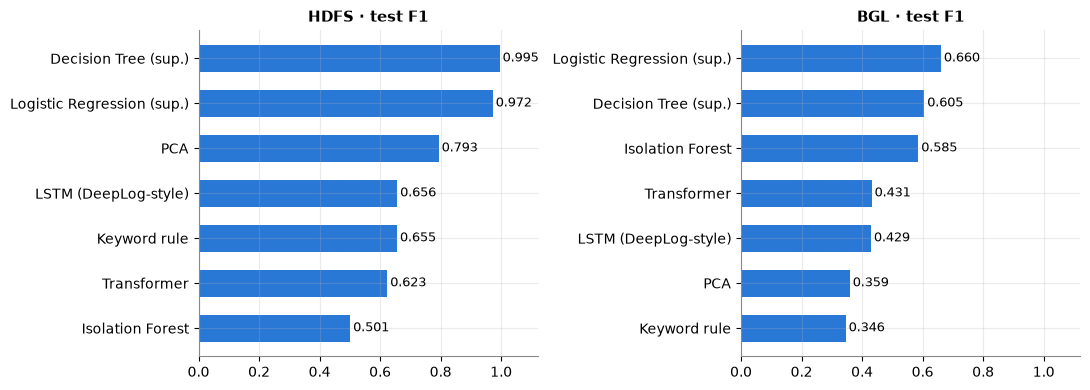

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, ds in zip(axes, ("hdfs", "bgl")):
    r = load_results(ds).sort_values("f1")
    ax.barh(r.model.str.replace(" (supervised)", " (sup.)").str.replace(" (ERROR/FATAL/fail/exception)", ""), r.f1, color=BLUE, height=0.6)
    for y, v in enumerate(r.f1):
        ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=9)
    ax.set(xlim=(0, 1.12), title=f"{ds.upper()} · test F1")
plt.tight_layout(); plt.show()

## Validation vs test
A large gap means the test period differs from what the threshold was tuned on.

In [4]:
for ds in ("hdfs", "bgl"):
    r = load_results(ds).dropna(subset=["val_f1"])
    display(r[["model", "val_f1", "f1"]].rename(columns={"f1": "test_f1"}).assign(gap=lambda d: d.test_f1 - d.val_f1).round(3))

,model,val_f1,test_f1,gap
1,PCA,0.723,0.793,0.070
2,Isolation Forest,0.825,0.501,-0.324
3,Logistic Regression (supervised),0.999,0.972,-0.027
4,Decision Tree (supervised),0.998,0.995,-0.004
5,LSTM (DeepLog-style),0.848,0.656,-0.192
6,Transformer,0.853,0.623,-0.230


,model,val_f1,test_f1,gap
1,PCA,0.321,0.359,0.038
2,Isolation Forest,0.795,0.585,-0.210
3,Logistic Regression (supervised),0.935,0.660,-0.275
4,Decision Tree (supervised),0.934,0.605,-0.329
5,LSTM (DeepLog-style),0.751,0.429,-0.322
6,Transformer,0.768,0.431,-0.336
